# Soal 1: Analisis Dataset clv_data.csv

**Nama:** Christina Adelia Sitinjak  
**NIM:** 42324056  
**Mata Kuliah:** 4233201 - Kecerdasan Buatan  
**Topik:** Missing Value, Outlier, dan Hierarchical Clustering

> Letakkan file `clv_data.csv` di folder yang sama dengan notebook ini, lalu jalankan sel dari atas ke bawah (Run All).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset clv_data.csv
df = pd.read_csv('clv_data.csv')
df.head()

,Unnamed: 0,id,age,gender,income,days_on_platform,city,purchases
0,0,0,NaN,Male,126895,14.0,San Francisco,0
1,1,1,NaN,Male,161474,14.0,Tokyo,0
2,2,2,24.0,Male,104723,34.0,London,1
3,3,3,29.0,Male,43791,28.0,London,2
4,4,4,18.0,Female,132181,26.0,London,2


#### Penjelasan:

Kode di atas untuk menyiapkan library yang dipakai, lalu membaca file `clv_data.csv` dan melihat sekilas isinya.

Empat baris pertama adalah proses *import*. `pandas` (disingkat `pd`) untuk mengolah data berbentuk tabel, `numpy` (disingkat `np`) untuk hitungan angka, `matplotlib.pyplot` (disingkat `plt`) untuk membuat grafik, dan `seaborn` (disingkat `sns`) untuk membuat grafik yang tampilannya lebih rapi. Library ini cukup di-import sekali di awal, jadi di sel-sel berikutnya tidak perlu ditulis lagi.

Baris `df = pd.read_csv('clv_data.csv')` membaca file CSV dan menyimpannya di variabel `df` (singkatan dari *DataFrame*, yaitu tabel di pandas). Setelah itu, `df.head()` menampilkan 5 baris paling atas untuk memastikan file terbaca dengan benar.

**Cara membaca hasil:** setiap baris adalah satu pelanggan. Kolomnya ada `Unnamed: 0` (nomor urut yang ikut tersimpan di file), `id`, `age` (usia), `gender` (jenis kelamin), `income` (pendapatan), `days_on_platform` (jumlah hari pelanggan memakai platform), `city` (kota tempat tinggal), dan `purchases` (jumlah pembelian). Perhatikan juga tulisan `NaN` pada kolom `age` di baris-baris awal. `NaN` artinya data di sel itu kosong (missing value).

**Catatan:** file `clv_data.csv` harus berada di folder yang sama dengan notebook ini, kalau tidak akan muncul error `FileNotFoundError`.


In [2]:
# Kolom "Unnamed: 0" hanya nomor urut bawaan file, jadi dihapus
df = df.drop(columns='Unnamed: 0')

# Melihat ukuran data dan informasi tiap kolom
print("Ukuran data (baris, kolom):", df.shape)
df.info()

Ukuran data (baris, kolom): (5000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                5000 non-null   int64  
 1   age               2554 non-null   float64
 2   gender            5000 non-null   str    
 3   income            5000 non-null   int64  
 4   days_on_platform  4859 non-null   float64
 5   city              5000 non-null   str    
 6   purchases         5000 non-null   int64  
dtypes: float64(2), int64(3), str(2)
memory usage: 273.6 KB


#### Penjelasan:

Kode di atas untuk membuang kolom yang tidak berguna, lalu melihat ukuran dan informasi dasar dari data.

Kolom `Unnamed: 0` muncul karena file CSV ini dulunya disimpan bersama nomor indeks barisnya. Isinya hanya angka urut 0, 1, 2, dan seterusnya, jadi tidak membawa informasi tentang pelanggan. Kalau dibiarkan, kolom ini bisa ikut terhitung sebagai data numerik, misalnya saat mencari outlier. Karena itu dibuang memakai `df.drop(columns='Unnamed: 0')`, dan hasilnya disimpan kembali ke `df`.

Baris `df.shape` menampilkan jumlah baris dan kolom. Lalu `df.info()` menampilkan ringkasan tiap kolom, yaitu nama kolom, jumlah data yang terisi (*Non-Null Count*), dan tipe datanya.

**Cara membaca hasil:** datanya ada 5.000 baris dan 7 kolom. Pada bagian `Non-Null Count`, kolom `age` hanya terisi 2.554 dari 5.000 baris, jadi ada 2.446 data yang kosong. Kolom `days_on_platform` terisi 4.859 baris, jadi 141 data kosong. Kolom lainnya terisi penuh (5.000). Tipe `float64` adalah angka desimal (kolom yang punya data kosong otomatis jadi float), `int64` adalah angka bulat, dan `str` (atau `object` di pandas versi lama) adalah teks.


---
## a. Deteksi Missing Value dan Outlier

In [3]:
# a. Deteksi missing value
missing = df.isnull().sum()
persen_missing_sebelum = (df.isnull().sum() / len(df) * 100).round(2)

hasil_missing = pd.DataFrame({
    'Jumlah Missing': missing,
    'Persentase (%)': persen_missing_sebelum
})
hasil_missing

,Jumlah Missing,Persentase (%)
id,0,0.00
age,2446,48.92
gender,0,0.00
income,0,0.00
days_on_platform,141,2.82
city,0,0.00
purchases,0,0.00


#### Penjelasan:

Kode di atas untuk mendeteksi missing value, yaitu mencari tahu kolom mana yang punya data kosong dan berapa banyak jumlahnya.

Bagian `df.isnull()` memeriksa setiap sel dan menghasilkan `True` kalau selnya kosong dan `False` kalau ada isinya. Lalu `.sum()` menjumlahkan hasilnya per kolom. Karena `True` dihitung 1 dan `False` dihitung 0, hasil penjumlahannya sama dengan banyaknya sel kosong di tiap kolom. Hasilnya disimpan di `missing`.

Untuk persentasenya, jumlah sel kosong dibagi jumlah seluruh baris (`len(df)`) lalu dikali 100, dan dibulatkan 2 angka di belakang koma dengan `.round(2)`. Hasilnya disimpan di `persen_missing_sebelum`. Variabel ini sengaja disimpan karena akan dipakai lagi di bagian c untuk dibandingkan dengan kondisi sesudah handling.

Kedua hasil itu digabung menjadi satu tabel kecil `hasil_missing` memakai `pd.DataFrame({...})`, supaya jumlah dan persentasenya terlihat berdampingan.

**Cara membaca hasil:** kolom `age` punya 2.446 data kosong atau **48,92 persen**, jadi hampir separuh pelanggan tidak punya data usia. Kolom `days_on_platform` punya 141 data kosong atau **2,82 persen**. Kolom `id`, `gender`, `income`, `city`, dan `purchases` tidak punya data kosong (0 persen). Persentase `age` yang sangat besar ini perlu diperhatikan, karena makin banyak data yang diisi tebakan, makin berkurang keasliannya.


In [4]:
# a. Deteksi outlier dengan metode IQR
kolom_numerik = ['age', 'income', 'days_on_platform', 'purchases']

def batas_iqr(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

hasil_outlier = []
for kolom in kolom_numerik:
    batas_bawah, batas_atas = batas_iqr(df[kolom].dropna())
    jumlah = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
    hasil_outlier.append([kolom, batas_bawah, batas_atas, jumlah])

pd.DataFrame(hasil_outlier, columns=['Kolom', 'Batas Bawah', 'Batas Atas', 'Jumlah Outlier'])

,Kolom,Batas Bawah,Batas Atas,Jumlah Outlier
0,age,-14.0,74.0,0
1,income,-91228.5,239387.5,77
2,days_on_platform,-27.5,72.5,87
3,purchases,-3.0,5.0,10


#### Penjelasan:

Kode di atas untuk mendeteksi outlier, yaitu nilai yang jauh berbeda dari kebanyakan data. Metode yang dipakai adalah IQR (*Interquartile Range*).

Cara kerja metode IQR begini. Kuartil 1 (Q1) adalah nilai di posisi 25 persen dan kuartil 3 (Q3) adalah nilai di posisi 75 persen. Selisih keduanya disebut IQR, yaitu `Q3 - Q1`, yang menggambarkan lebar bagian tengah data. Nilai yang lebih kecil dari `Q1 - 1,5 x IQR` atau lebih besar dari `Q3 + 1,5 x IQR` dianggap outlier.

Di dalam kode, fungsi `batas_iqr(data)` dibuat untuk menghitung dua batas itu. Fungsi ini mengembalikan batas bawah dan batas atas. Dengan fungsi, perhitungan yang sama bisa dipakai lagi tanpa menulis ulang, bahkan nanti dipakai juga di bagian d.

Selanjutnya, perulangan `for kolom in kolom_numerik` memeriksa empat kolom angka satu per satu. Untuk tiap kolom, `df[kolom].dropna()` dipakai saat menghitung batas supaya data kosong tidak ikut dihitung. Lalu `((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()` menghitung berapa banyak nilai yang berada di luar batas. Tanda `|` berarti "atau". Hasil tiap kolom dikumpulkan di daftar `hasil_outlier`, lalu ditampilkan sebagai tabel.

**Cara membaca hasil:** kolom `age` punya **0 outlier**, karena usianya hanya berkisar 10 sampai 50 tahun. Kolom `income` punya **77 outlier**, yaitu pendapatan di atas sekitar 239.387,5 (nilai tertingginya 388.572). Kolom `days_on_platform` punya **87 outlier**, yaitu lebih dari 72,5 hari (tertinggi 111 hari). Kolom `purchases` punya 10 outlier, yaitu pelanggan yang membeli 6 kali (batas atasnya 5). Batas bawah pada `income` bernilai negatif (-91.228,5), jadi tidak mungkin ada pendapatan yang lebih kecil dari batas itu.


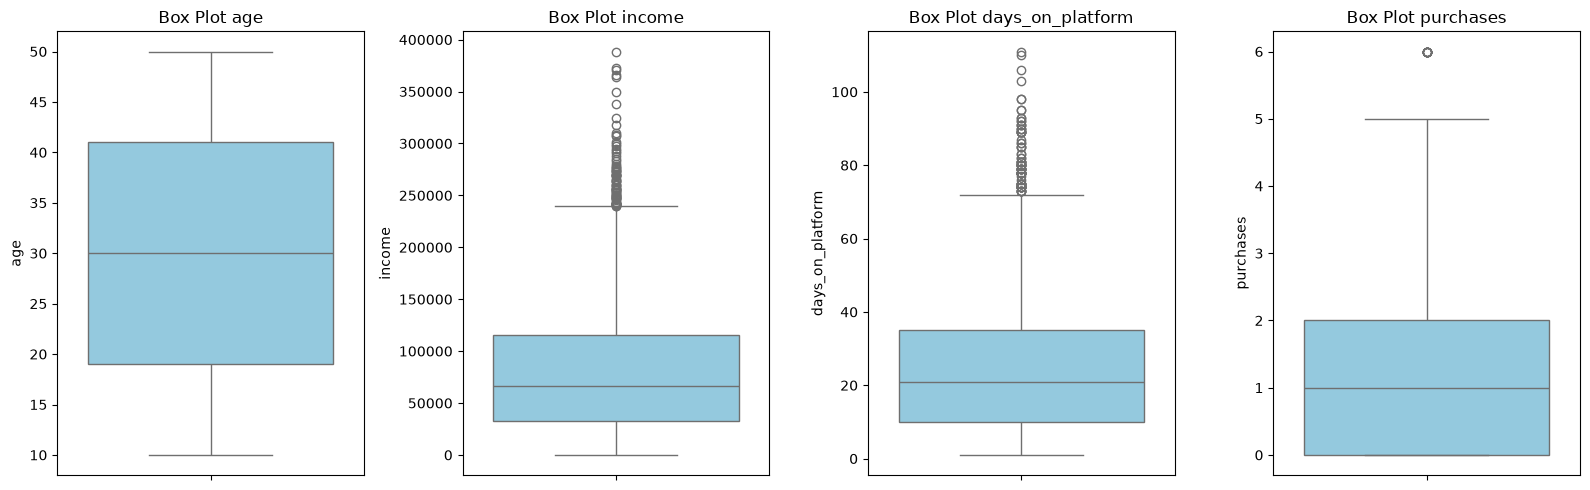

In [5]:
# a. Visualisasi outlier dengan box plot
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, kolom in zip(axes, kolom_numerik):
    sns.boxplot(y=df[kolom], ax=ax, color='skyblue')
    ax.set_title(f'Box Plot {kolom}')

plt.tight_layout()
plt.show()

#### Penjelasan:

Kode di atas untuk menampilkan outlier dalam bentuk gambar, yaitu box plot untuk keempat kolom angka.

Baris `plt.subplots(1, 4, figsize=(16, 5))` menyiapkan satu gambar berisi 4 grafik berjajar. Lalu perulangan `for ax, kolom in zip(axes, kolom_numerik)` memasangkan tiap grafik dengan satu kolom. Di dalamnya, `sns.boxplot(y=df[kolom], ax=ax, color='skyblue')` menggambar box plot kolom itu secara tegak berwarna biru muda, dan `ax.set_title(...)` memberi judul. Fungsi `plt.tight_layout()` merapikan jarak antar grafik dan `plt.show()` menampilkan gambarnya.

**Cara membaca hasil:** kotak menunjukkan 50 persen data di tengah (dari Q1 sampai Q3), garis di dalam kotak adalah median, garis tipis yang keluar dari kotak (*whisker*) menunjukkan rentang data yang masih wajar, dan titik-titik di luar whisker adalah outlier.

Pada `age`, tidak ada titik di luar whisker, jadi tidak ada outlier. Pada `income`, ada banyak titik di sisi atas, menandakan sebagian kecil pelanggan berpendapatan sangat tinggi. Pada `days_on_platform`, titik outlier juga hanya muncul di sisi atas. Pada `purchases`, hanya ada sedikit titik di atas, yaitu pelanggan dengan 6 kali pembelian. Pola outlier yang hanya ada di sisi atas ini menandakan data `income` dan `days_on_platform` miring ke kanan.


---
## b. Imputasi Missing Value (Mean atau Median)

                    Mean  Median  Skewness
age               30.202    30.0    -0.022
days_on_platform  24.390    21.0     1.026


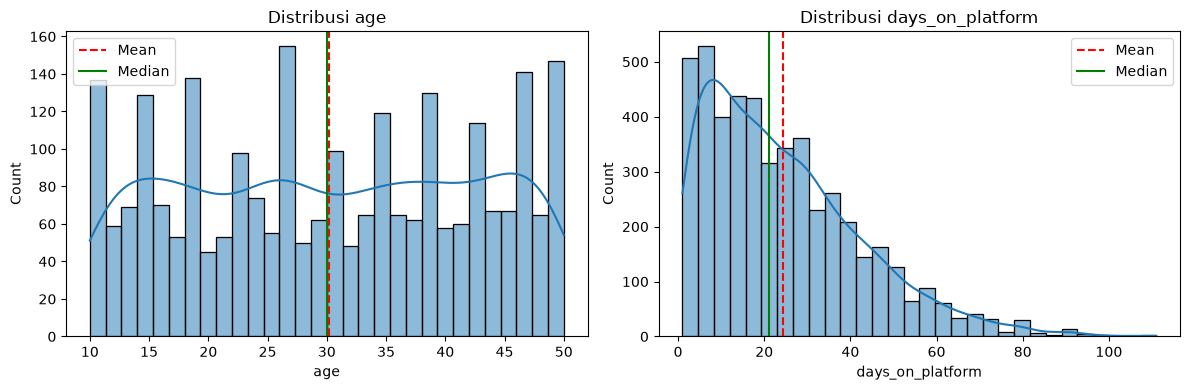

In [6]:
# b. Memeriksa bentuk sebaran data sebelum memilih mean atau median
kolom_missing = ['age', 'days_on_platform']

pemeriksaan = pd.DataFrame({
    'Mean': df[kolom_missing].mean(),
    'Median': df[kolom_missing].median(),
    'Skewness': df[kolom_missing].skew()
}).round(3)
print(pemeriksaan)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, kolom in zip(axes, kolom_missing):
    sns.histplot(df[kolom].dropna(), bins=30, kde=True, ax=ax)
    ax.axvline(df[kolom].mean(), color='red', linestyle='--', label='Mean')
    ax.axvline(df[kolom].median(), color='green', linestyle='-', label='Median')
    ax.set_title(f'Distribusi {kolom}')
    ax.legend()
plt.tight_layout()
plt.show()

#### Penjelasan:

Kode di atas untuk memeriksa bentuk sebaran data pada dua kolom yang punya missing value, yaitu `age` dan `days_on_platform`. Pemeriksaan ini dilakukan dulu supaya kita punya alasan yang jelas dalam memilih antara mean atau median untuk mengisi data yang kosong.

Pada bagian pertama, tabel `pemeriksaan` berisi tiga ukuran untuk tiap kolom. `Mean` adalah rata-rata, `Median` adalah nilai tengah, dan `Skewness` adalah ukuran kemiringan sebaran. Nilai skewness mendekati 0 berarti sebarannya simetris, nilai positif berarti miring ke kanan (ekor panjang di sisi nilai besar), dan nilai negatif berarti miring ke kiri.

Pada bagian kedua dibuat histogram untuk tiap kolom. `sns.histplot(..., bins=30, kde=True)` menggambar batang histogram dan garis halus (*kde*) yang menunjukkan bentuk sebarannya. Garis merah putus-putus (`axvline`) menandai posisi mean dan garis hijau menandai posisi median.

**Cara membaca hasil:** pada `age`, mean (30,202) hampir sama dengan median (30), dan skewness-nya -0,022 yang sangat dekat dengan 0. Artinya sebaran usia simetris dan tidak ada nilai ekstrem. Di histogram, garis merah dan hijau hampir menumpuk. Pada `days_on_platform`, mean (24,39) lebih besar daripada median (21) dan skewness-nya 1,026 (positif). Artinya sebarannya miring ke kanan karena ada sebagian pelanggan yang sangat lama di platform (sampai 111 hari) yang menarik rata-rata ke atas. Di histogram, garis merah terlihat bergeser ke kanan dari garis hijau.


In [7]:
# b. Imputasi missing value
df_imputasi = df.copy()

# age: sebarannya simetris, jadi diisi dengan mean
df_imputasi['age'] = df_imputasi['age'].fillna(df_imputasi['age'].mean())

# days_on_platform: sebarannya miring ke kanan dan ada outlier, jadi diisi dengan median
df_imputasi['days_on_platform'] = df_imputasi['days_on_platform'].fillna(df_imputasi['days_on_platform'].median())

df_imputasi.isnull().sum()

id                  0
age                 0
gender              0
income              0
days_on_platform    0
city                0
purchases           0
dtype: int64

#### Penjelasan:

Kode di atas untuk mengisi (imputasi) data yang kosong. Kolom `age` diisi dengan mean, dan kolom `days_on_platform` diisi dengan median.

Baris `df_imputasi = df.copy()` membuat salinan data. Dengan begitu data asli di `df` tetap utuh, dan kita masih bisa membandingkan kondisi sebelum dan sesudah handling di bagian c.

Pada `fillna(...)`, perintah ini mengisi sel yang kosong dengan nilai yang kita berikan. Untuk `age`, nilai pengisinya adalah `df_imputasi['age'].mean()`. Untuk `days_on_platform`, nilai pengisinya adalah `df_imputasi['days_on_platform'].median()`. Baris terakhir, `df_imputasi.isnull().sum()`, menghitung ulang jumlah data kosong untuk memastikan semuanya sudah terisi.

**Alasan pemilihan mean dan median:**

Untuk `age` dipilih **mean**. Dari langkah sebelumnya terlihat bahwa sebaran usia simetris (mean 30,2 hampir sama dengan median 30, skewness mendekati 0) dan tidak punya outlier. Pada kondisi seperti ini, mean mewakili pusat data dengan baik, dan memakai mean maupun median hasilnya hampir sama. Mean dipilih karena paling sederhana dan tidak mengubah rata-rata usia keseluruhan data.

Untuk `days_on_platform` dipilih **median**. Sebarannya miring ke kanan dan punya outlier (sampai 111 hari). Mean sangat mudah tertarik oleh nilai-nilai ekstrem, sehingga nilainya (24,39) lebih tinggi daripada kebanyakan pelanggan. Median tidak terpengaruh nilai ekstrem, jadi nilainya (21) lebih mewakili pelanggan yang umum. Aturan praktisnya: data simetris tanpa outlier, pakai mean. Data miring atau punya outlier, pakai median.

**Cara membaca hasil:** outputnya menunjukkan angka 0 untuk semua kolom, artinya sudah tidak ada data kosong yang tersisa.

**Catatan:** karena `age` kosong hampir 49 persen, mengisinya dengan satu nilai yang sama membuat sebaran usia menjadi lebih menumpuk di sekitar angka 30. Ini kelemahan imputasi dengan mean atau median, dan sebaiknya diingat saat menafsirkan hasil analisis yang memakai kolom usia.


---
## c. Persentase Missing Value Sebelum dan Sesudah Handling

In [8]:
# c. Persentase missing value sebelum dan sesudah handling
persen_missing_sesudah = (df_imputasi.isnull().sum() / len(df_imputasi) * 100).round(2)

perbandingan_missing = pd.DataFrame({
    'Sebelum (%)': persen_missing_sebelum,
    'Sesudah (%)': persen_missing_sesudah
})
perbandingan_missing

,Sebelum (%),Sesudah (%)
id,0.00,0.0
age,48.92,0.0
gender,0.00,0.0
income,0.00,0.0
days_on_platform,2.82,0.0
city,0.00,0.0
purchases,0.00,0.0


#### Penjelasan:

Kode di atas untuk menampilkan persentase missing value sebelum dan sesudah handling, dalam satu tabel perbandingan.

Persentase sesudah dihitung dengan cara yang sama seperti sebelumnya, tetapi memakai data `df_imputasi` yang sudah diisi: `(df_imputasi.isnull().sum() / len(df_imputasi) * 100).round(2)`. Hasilnya disimpan di `persen_missing_sesudah`. Lalu `pd.DataFrame({...})` menggabungkan `persen_missing_sebelum` (yang sudah dihitung di bagian a) dengan `persen_missing_sesudah` menjadi satu tabel dengan dua kolom.

**Cara membaca hasil:** pada kolom `age`, persentase missing berubah dari **48,92 persen menjadi 0 persen**. Pada kolom `days_on_platform`, persentasenya berubah dari **2,82 persen menjadi 0 persen**. Kolom lainnya memang sudah 0 persen dari awal. Jadi proses imputasi berhasil dan seluruh data sekarang lengkap.


---
## d. Remove Outlier (Plot Sebelum dan Sesudah)

In [9]:
# d. Remove outlier (metode IQR) pada income dan days_on_platform
df_bersih = df_imputasi.copy()

for kolom in ['income', 'days_on_platform']:
    batas_bawah, batas_atas = batas_iqr(df_bersih[kolom])
    df_bersih = df_bersih[(df_bersih[kolom] >= batas_bawah) & (df_bersih[kolom] <= batas_atas)]

print("Jumlah data sebelum remove outlier:", len(df_imputasi))
print("Jumlah data sesudah remove outlier:", len(df_bersih))
print("Jumlah data yang dihapus          :", len(df_imputasi) - len(df_bersih))

Jumlah data sebelum remove outlier: 5000
Jumlah data sesudah remove outlier: 4820
Jumlah data yang dihapus          : 180


#### Penjelasan:

Kode di atas untuk menghapus baris yang mengandung outlier pada kolom `income` dan `days_on_platform`, memakai metode IQR yang sama seperti di bagian a.

Variabel `df_bersih` dibuat dari salinan `df_imputasi`, supaya data sebelum penghapusan tetap tersimpan dan bisa dipakai untuk plot perbandingan di sel berikutnya.

Pada perulangan `for kolom in ['income', 'days_on_platform']`, fungsi `batas_iqr()` menghitung batas bawah dan batas atas untuk kolom itu. Lalu `df_bersih[(df_bersih[kolom] >= batas_bawah) & (df_bersih[kolom] <= batas_atas)]` hanya menyimpan baris yang nilainya berada di dalam batas. Tanda `&` berarti "dan", jadi syaratnya kedua batas harus terpenuhi. Baris yang berada di luar batas tidak ikut disimpan (artinya dibuang). Setelah itu tiga baris `print` menampilkan jumlah data sebelum, sesudah, dan yang dihapus.

Kolom yang dibersihkan hanya `income` dan `days_on_platform`, karena itulah dua kolom yang akan dipakai untuk klasterisasi di bagian e. Kolom `age` tidak punya outlier. Kolom `purchases` dibiarkan karena nilainya berupa hitungan bulat (jumlah pembelian) dan nilai 6 kali masih masuk akal sebagai perilaku pelanggan.

**Cara membaca hasil:** jumlah data sebelumnya 5.000 baris dan sesudahnya **4.820 baris**, jadi ada **180 baris** yang dihapus (sekitar 3,6 persen dari seluruh data). Jumlahnya sedikit lebih besar daripada 77 + 87 outlier di bagian a, karena batas IQR `days_on_platform` sedikit berubah setelah data kosongnya diisi median, dan sebagian baris punya outlier di dua kolom sekaligus.


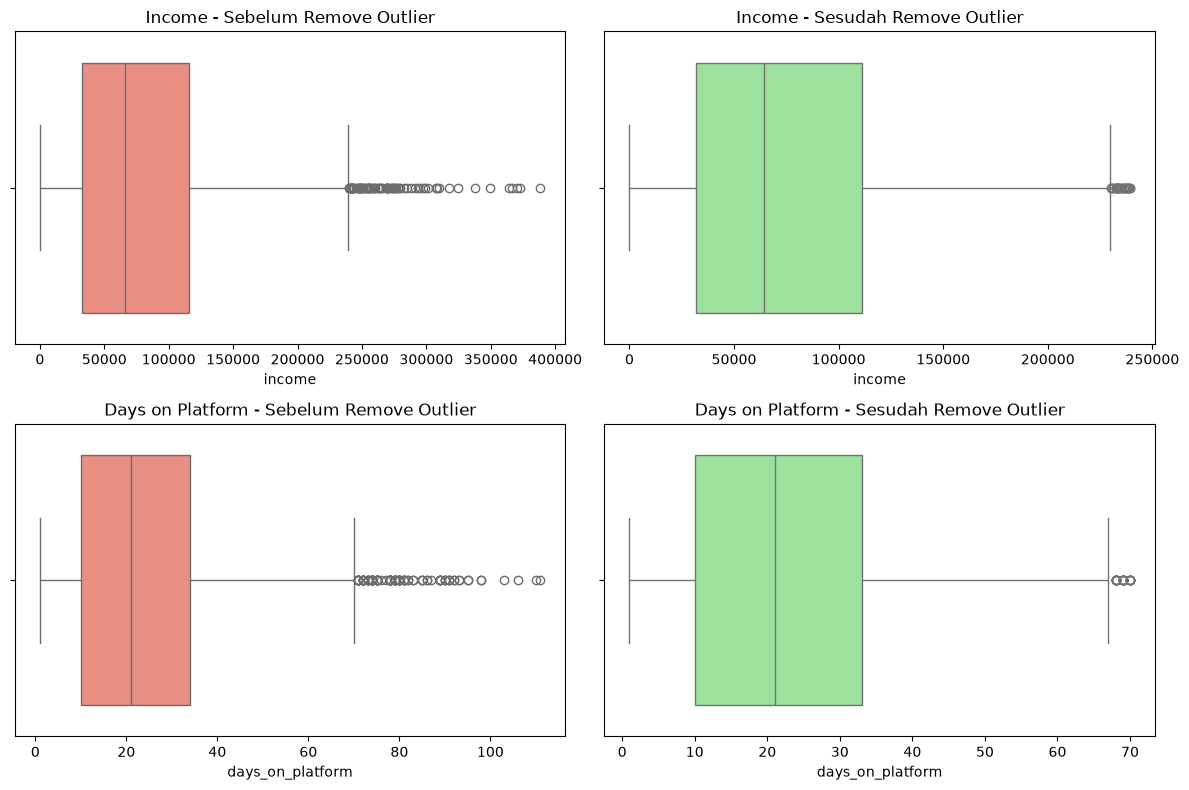

In [10]:
# d. Plot sebelum dan sesudah remove outlier
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(x=df_imputasi['income'], ax=axes[0, 0], color='salmon')
axes[0, 0].set_title('Income - Sebelum Remove Outlier')

sns.boxplot(x=df_bersih['income'], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Income - Sesudah Remove Outlier')

sns.boxplot(x=df_imputasi['days_on_platform'], ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Days on Platform - Sebelum Remove Outlier')

sns.boxplot(x=df_bersih['days_on_platform'], ax=axes[1, 1], color='lightgreen')
axes[1, 1].set_title('Days on Platform - Sesudah Remove Outlier')

plt.tight_layout()
plt.show()

#### Penjelasan:

Kode di atas untuk membandingkan box plot `income` dan `days_on_platform` sebelum dan sesudah outlier dihapus.

Baris `plt.subplots(2, 2, figsize=(12, 8))` menyiapkan gambar berisi 4 grafik (2 baris, 2 kolom). Kolom kiri untuk kondisi **sebelum** remove outlier (memakai `df_imputasi`, berwarna merah muda), dan kolom kanan untuk kondisi **sesudah** remove outlier (memakai `df_bersih`, berwarna hijau muda). Baris atas untuk `income` dan baris bawah untuk `days_on_platform`. Penentuan posisi grafik dilakukan dengan `ax=axes[baris, kolom]`, dan `sns.boxplot(x=...)` menggambar box plot secara mendatar.

**Cara membaca hasil:** pada `income` sebelum dihapus, ada banyak titik outlier yang memanjang sampai sekitar 390.000. Sesudah dihapus, sumbu hanya sampai sekitar 240.000 dan titik-titik yang jauh sudah hilang. Pada `days_on_platform`, sebelum dihapus titik outlier memanjang sampai sekitar 110 hari, dan sesudah dihapus hanya sampai sekitar 70 hari.

Perhatikan bahwa pada gambar sesudah dihapus masih ada beberapa titik di ujung kanan. Itu bukan kesalahan. Box plot menghitung batas IQR-nya ulang dari data yang baru. Karena data sudah lebih sempit, batasnya ikut bergeser sedikit, sehingga beberapa nilai di ujung tampak sebagai outlier lagi. Hal ini wajar, dan penghapusan satu kali sudah cukup. Menghapus berulang-ulang justru akan membuang terlalu banyak data.


---
## e. Klasterisasi Income dan Days on Platform (Hierarchical Clustering)

In [11]:
# e. Persiapan data untuk hierarchical clustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

data_cluster = df_bersih[['income', 'days_on_platform']]

# Standarisasi supaya income (puluhan ribu) dan days_on_platform (puluhan) setara skalanya
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_cluster)

pd.DataFrame(X_scaled, columns=['income', 'days_on_platform']).head()

,income,days_on_platform
0,0.912984,-0.567513
1,1.536938,-0.567513
2,0.512905,0.681050
3,-0.586570,0.306481
4,1.008366,0.181625


#### Penjelasan:

Kode di atas untuk menyiapkan data sebelum dikelompokkan dengan hierarchical clustering.

Bagian awal meng-import beberapa alat. `StandardScaler` untuk standarisasi data, `linkage` dan `dendrogram` dari library `scipy` untuk membuat dendrogram, `AgglomerativeClustering` untuk membentuk klaster, dan `silhouette_score` untuk menilai kualitas klaster.

Baris `data_cluster = df_bersih[['income', 'days_on_platform']]` memilih dua kolom yang diminta soal, yaitu `income` dan `days_on_platform`, dari data yang sudah bersih.

Langkah berikutnya adalah standarisasi. Hierarchical clustering mengelompokkan data berdasarkan jarak. Masalahnya, `income` bernilai puluhan ribu sedangkan `days_on_platform` hanya puluhan. Kalau dibiarkan, jarak akan hampir seluruhnya ditentukan oleh `income`, dan `days_on_platform` seakan tidak ikut berpengaruh. `StandardScaler` mengubah tiap kolom sehingga rata-ratanya 0 dan sebarannya (standar deviasi) 1, jadi kedua kolom punya bobot yang adil. Perintah `fit_transform` menghitung rata-rata dan sebaran lalu langsung mengubah datanya. Hasilnya disimpan di `X_scaled`.

**Cara membaca hasil:** tabel yang tampil berisi 5 baris pertama setelah distandarisasi. Angkanya bukan lagi pendapatan atau jumlah hari, melainkan skor standar. Angka positif berarti di atas rata-rata dan angka negatif berarti di bawah rata-rata. Misalnya pada baris pertama, income bernilai 0,91 (di atas rata-rata) dan days_on_platform bernilai -0,57 (di bawah rata-rata).


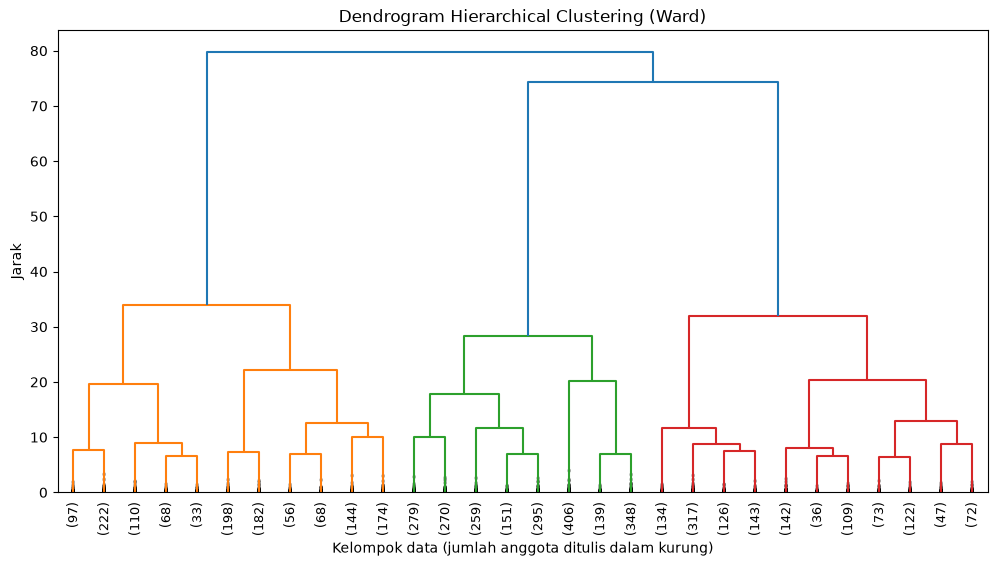

In [12]:
# e. Dendrogram (metode ward)
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title('Dendrogram Hierarchical Clustering (Ward)')
plt.xlabel('Kelompok data (jumlah anggota ditulis dalam kurung)')
plt.ylabel('Jarak')
plt.show()

#### Penjelasan:

Kode di atas untuk membuat dendrogram, yaitu diagram pohon yang menunjukkan proses penggabungan data menjadi klaster pada hierarchical clustering.

Baris `linkage(X_scaled, method='ward')` menghitung proses penggabungannya. Hierarchical clustering (jenis *agglomerative*) bekerja dari bawah ke atas. Awalnya setiap data dianggap satu klaster sendiri, lalu dua klaster yang paling mirip digabung, dan proses ini diulang sampai tersisa satu klaster besar. Metode `ward` menggabungkan dua klaster yang menyebabkan kenaikan keragaman di dalam klaster paling kecil, sehingga klaster yang dihasilkan cenderung rapat dan seimbang.

Fungsi `dendrogram(...)` menggambar hasilnya. Karena datanya hampir 5.000 titik, menggambar semuanya akan menjadi gambar yang tidak terbaca. Maka dipakai `truncate_mode='lastp', p=30`, yang artinya hanya 30 penggabungan terakhir yang ditampilkan, dan klaster kecil di bawahnya diringkas. Angka dalam kurung di sumbu bawah adalah jumlah data dalam kelompok yang diringkas itu. Pengaturan `leaf_rotation=90` memutar tulisan agar muat.

**Cara membaca hasil:** sumbu tegak adalah jarak penggabungan. Makin tinggi sebuah garis horizontal, makin berbeda dua kelompok yang digabung di situ. Cara menentukan jumlah klaster adalah "memotong" dendrogram dengan garis horizontal imajiner di tempat yang jaraknya melompat jauh, lalu menghitung berapa cabang yang terpotong.

Pada gambar ini, penggabungan terakhir terjadi di jarak sekitar 80 dan sebelumnya di sekitar 74, sedangkan cabang-cabang di bawahnya bergabung di jarak sekitar 30-an. Lompatan besar itu menunjukkan bahwa kalau dipotong di ketinggian sekitar 50, terpotong **3 cabang**, yang ditandai tiga warna (oranye, hijau, merah). Itu sebabnya dugaan jumlah klaster yang masuk akal adalah 3. Dugaan ini diperkuat dengan silhouette score di sel berikutnya.


In [13]:
# e. Menentukan jumlah klaster dengan silhouette score
for k in range(2, 8):
    label = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    print(f"Jumlah klaster = {k} -> silhouette score = {silhouette_score(X_scaled, label):.4f}")

Jumlah klaster = 2 -> silhouette score = 0.3498
Jumlah klaster = 3 -> silhouette score = 0.3935
Jumlah klaster = 4 -> silhouette score = 0.3658
Jumlah klaster = 5 -> silhouette score = 0.3102
Jumlah klaster = 6 -> silhouette score = 0.2836
Jumlah klaster = 7 -> silhouette score = 0.2643


#### Penjelasan:

Kode di atas untuk menentukan jumlah klaster yang paling baik memakai silhouette score, sebagai pembanding dugaan dari dendrogram.

Silhouette score menilai seberapa baik sebuah titik cocok dengan klasternya sendiri dibandingkan dengan klaster tetangganya. Nilainya berkisar dari -1 sampai 1. Makin mendekati 1 berarti klaster makin rapat dan terpisah jelas. Nilai di sekitar 0 berarti klaster saling tumpang tindih, dan nilai negatif berarti banyak titik salah klaster.

Dalam kode, perulangan `for k in range(2, 8)` mencoba jumlah klaster dari 2 sampai 7. Untuk tiap `k`, `AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)` membentuk klaster dan menghasilkan nomor klaster untuk tiap data. Lalu `silhouette_score(X_scaled, label)` menghitung nilainya. Perintah `print(f"...")` menampilkan hasilnya, dengan `:.4f` untuk membulatkan sampai 4 angka di belakang koma.

**Cara membaca hasil:** skor tertinggi ada pada **3 klaster dengan nilai 0,3935**. Sebagai perbandingan, 2 klaster bernilai 0,3498, 4 klaster 0,3658, dan sesudah itu terus menurun sampai 0,2643 untuk 7 klaster. Jadi jumlah klaster terbaik adalah 3, sama dengan dugaan dari dendrogram. Nilai 0,39 termasuk sedang. Artinya klaster terbentuk cukup jelas, tetapi batasnya tidak benar-benar tegas, dan hal ini terlihat nanti di grafik.


In [14]:
# e. Membentuk klaster dengan hierarchical clustering (3 klaster)
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_bersih = df_bersih.copy()
df_bersih['cluster'] = hc.fit_predict(X_scaled)

df_bersih['cluster'].value_counts().sort_index()

cluster
0    1352
1    1321
2    2147
Name: count, dtype: int64

#### Penjelasan:

Kode di atas untuk membentuk klaster dengan hierarchical clustering memakai 3 klaster, lalu memasukkan nomor klaster ke dalam tabel data.

Baris `AgglomerativeClustering(n_clusters=3, linkage='ward')` membuat modelnya. Pengaturan `n_clusters=3` berarti hasil akhirnya dipotong menjadi 3 klaster, dan `linkage='ward'` sama dengan metode di dendrogram. Lalu `hc.fit_predict(X_scaled)` menjalankan proses pengelompokan dan menghasilkan nomor klaster (0, 1, atau 2) untuk setiap pelanggan. Nomor ini disimpan sebagai kolom baru bernama `cluster` di `df_bersih`. Baris `df_bersih = df_bersih.copy()` sebelumnya hanya dipakai untuk menghindari peringatan pandas saat menambah kolom.

Baris terakhir, `value_counts().sort_index()`, menghitung jumlah anggota tiap klaster dan mengurutkannya berdasarkan nomor klaster.

**Cara membaca hasil:** klaster 0 berisi **1.352** pelanggan, klaster 1 berisi **1.321** pelanggan, dan klaster 2 berisi **2.147** pelanggan. Totalnya 4.820, sama dengan jumlah data setelah outlier dihapus. Nomor klaster hanyalah penanda. Arti dari tiap klaster baru bisa dipahami dari profilnya di sel berikutnya.


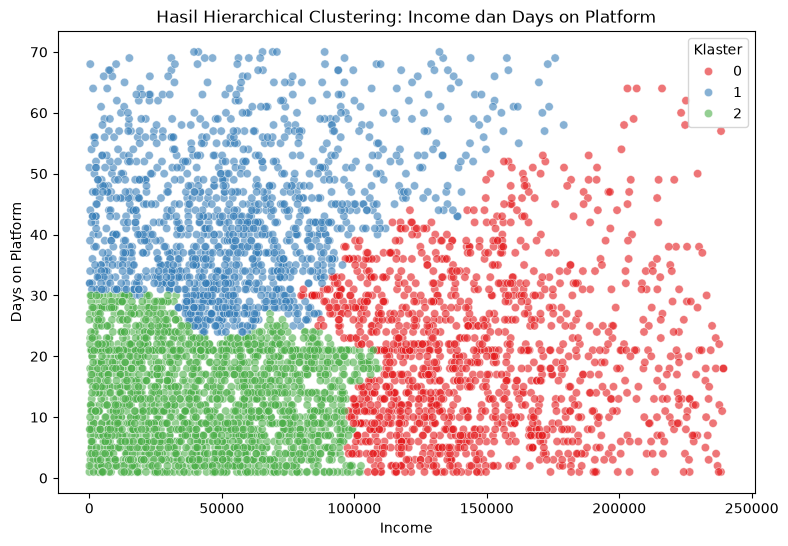

In [15]:
# e. Visualisasi hasil klaster
plt.figure(figsize=(9, 6))
sns.scatterplot(x='income', y='days_on_platform', hue='cluster',
                data=df_bersih, palette='Set1', alpha=0.6)
plt.title('Hasil Hierarchical Clustering: Income dan Days on Platform')
plt.xlabel('Income')
plt.ylabel('Days on Platform')
plt.legend(title='Klaster')
plt.show()

#### Penjelasan:

Kode di atas untuk menampilkan hasil klaster dalam bentuk grafik titik, dengan warna berbeda untuk tiap klaster.

Baris `sns.scatterplot(x='income', y='days_on_platform', hue='cluster', data=df_bersih, palette='Set1', alpha=0.6)` menggambar satu titik untuk tiap pelanggan. Sumbu x adalah `income` dan sumbu y adalah `days_on_platform`. Pengaturan `hue='cluster'` mewarnai titik menurut klasternya, `palette='Set1'` memilih set warna, dan `alpha=0.6` membuat titik agak transparan supaya area yang padat terlihat lebih pekat. Sisanya memberi judul, nama sumbu, dan judul legenda.

**Cara membaca hasil:** terlihat tiga daerah warna.

Klaster 2 (hijau) berada di kiri bawah, yaitu pelanggan dengan income lebih rendah dan masa di platform yang pendek (di bawah sekitar 30 hari). Klaster 1 (biru) berada di kiri atas, yaitu pelanggan yang sudah lama di platform (sekitar 30 sampai 70 hari) dengan income rendah sampai menengah. Klaster 0 (merah) berada di sisi kanan, yaitu pelanggan dengan income tinggi (mulai sekitar 100.000 ke atas).

Batas antar klaster berupa gradasi, bukan garis tegas. Hal ini sesuai dengan silhouette score yang sedang (0,39), yaitu titik-titik di perbatasan bisa masuk ke klaster yang berdekatan.


In [16]:
# e. Profil setiap klaster untuk dianalisa
profil = df_bersih.groupby('cluster').agg(
    jumlah_pelanggan=('id', 'count'),
    rata2_income=('income', 'mean'),
    rata2_days_on_platform=('days_on_platform', 'mean'),
    rata2_purchases=('purchases', 'mean')
).round(2)
profil

,jumlah_pelanggan,rata2_income,rata2_days_on_platform,rata2_purchases
cluster,,,,
0,1352,147542.45,19.98,1.12
1,1321,55452.75,42.42,1.07
2,2147,44260.33,13.15,1.10


#### Penjelasan:

Kode di atas untuk membuat profil tiap klaster, yaitu merangkum karakteristik rata-rata pelanggan di setiap klaster. Profil ini dasar dari analisa hasil klasterisasi.

Perintah `df_bersih.groupby('cluster')` mengelompokkan baris berdasarkan nomor klaster. Lalu `.agg(...)` menghitung beberapa ringkasan sekaligus untuk tiap kelompok dan memberi nama pada kolom hasilnya: `jumlah_pelanggan` (menghitung `id`), `rata2_income`, `rata2_days_on_platform`, dan `rata2_purchases` (rata-rata kolom masing-masing). Fungsi `.round(2)` membulatkan hasilnya menjadi 2 angka di belakang koma.

**Cara membaca hasil dan analisa:**

Klaster 0 berisi 1.352 pelanggan dengan rata-rata income sekitar **147.542** dan rata-rata hari di platform sekitar **20 hari**. Kelompok ini adalah **pelanggan berpendapatan tinggi** dengan lama di platform yang sedang. Daya belinya besar, jadi cocok jadi target penawaran produk premium.

Klaster 1 berisi 1.321 pelanggan dengan rata-rata income sekitar **55.453** dan rata-rata hari di platform sekitar **42 hari**. Kelompok ini adalah **pelanggan setia berpendapatan menengah ke bawah**, yang paling lama bertahan di platform. Cocok untuk program loyalitas atau promo hemat.

Klaster 2 berisi 2.147 pelanggan (kelompok terbesar) dengan rata-rata income sekitar **44.260** dan rata-rata hari di platform hanya sekitar **13 hari**. Kelompok ini adalah **pelanggan baru berpendapatan rendah**. Cocok untuk kampanye supaya mereka mau bertahan lebih lama.

**Kesimpulan:** pelanggan terbagi menjadi tiga kelompok berdasarkan kombinasi pendapatan dan lama di platform. Rata-rata `purchases` di ketiga klaster hampir sama (sekitar 1,07 sampai 1,12), karena kolom `purchases` memang tidak dipakai dalam proses klasterisasi dan tidak berhubungan dengan dua kolom lainnya. Artinya, besar pendapatan dan lamanya bergabung tidak otomatis membuat pelanggan lebih sering membeli di data ini.
